# Detección de neumonía en radiografías de tórax
Comparación de una CNN entrenada desde cero contra transfer learning (MobileNetV2).

Dataset: Chest X-Ray Images (Pneumonia), Kermany et al. (2018).

In [1]:
import os
import time
import glob
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import kagglehub
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score, ConfusionMatrixDisplay

tf.keras.utils.set_random_seed(42)
os.makedirs("figuras", exist_ok=True)

C:\Users\maxjo\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
ruta = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
ruta = os.path.join(ruta, "chest_xray")
clases = ["NORMAL", "PNEUMONIA"]

def listar(particion):
    rutas, etiquetas = [], []
    for i, c in enumerate(clases):
        archivos = sorted(glob.glob(os.path.join(ruta, particion, c, "*.jpeg")))
        rutas += archivos
        etiquetas += [i] * len(archivos)
    return np.array(rutas), np.array(etiquetas)

for particion in ["train", "val", "test"]:
    r, e = listar(particion)
    print(f"{particion:5s}: {len(r):5d} imagenes  NORMAL = {(e == 0).sum():4d}  PNEUMONIA = {(e == 1).sum():4d}")

train:  5216 imagenes  NORMAL = 1341  PNEUMONIA = 3875
val  :    16 imagenes  NORMAL =    8  PNEUMONIA =    8
test :   624 imagenes  NORMAL =  234  PNEUMONIA =  390


## División de datos
La carpeta `val` original solo tiene 16 imágenes, así que se juntan `train` y `val` y se separa un 15 % estratificado para validación. La carpeta `test` se deja intacta para la evaluación final.

In [3]:
rutas_tr, y_tr = listar("train")
rutas_va, y_va = listar("val")
rutas_te, y_te = listar("test")

rutas_todas = np.concatenate([rutas_tr, rutas_va])
y_todas = np.concatenate([y_tr, y_va])
rutas_train, rutas_val, y_train, y_val = train_test_split(rutas_todas, y_todas, test_size=0.15, stratify=y_todas, random_state=42)
rutas_test, y_test = rutas_te, y_te

for nombre, y in [("entrenamiento", y_train), ("validacion", y_val), ("prueba", y_test)]:
    print(f"{nombre:13s}: {len(y):5d}  NORMAL = {(y == 0).sum():4d} ({(y == 0).mean() * 100:.1f} %)  PNEUMONIA = {(y == 1).sum():4d} ({(y == 1).mean() * 100:.1f} %)")

entrenamiento:  4447  NORMAL = 1147 (25.8 %)  PNEUMONIA = 3300 (74.2 %)
validacion   :   785  NORMAL =  202 (25.7 %)  PNEUMONIA =  583 (74.3 %)
prueba       :   624  NORMAL =  234 (37.5 %)  PNEUMONIA =  390 (62.5 %)


In [4]:
IMG = 160
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE

def cargar(ruta_img, etiqueta):
    # escala de grises redimensionada y guardada como uint8 para que quepa en memoria
    img = tf.io.decode_jpeg(tf.io.read_file(ruta_img), channels=1)
    img = tf.image.resize(img, (IMG, IMG))
    return tf.cast(img, tf.uint8), etiqueta

def a_rgb(img, etiqueta):
    # mobilenetv2 espera 3 canales
    return tf.image.grayscale_to_rgb(tf.cast(img, tf.float32)), etiqueta

def crear_dataset(rutas, y, mezclar):
    ds = tf.data.Dataset.from_tensor_slices((rutas, y.astype("float32")))
    ds = ds.map(cargar, num_parallel_calls=AUTOTUNE).cache()
    if mezclar:
        ds = ds.shuffle(len(rutas), seed=42)
    return ds.map(a_rgb, num_parallel_calls=AUTOTUNE).batch(BATCH).prefetch(AUTOTUNE)

train_ds = crear_dataset(rutas_train, y_train, True)
val_ds = crear_dataset(rutas_val, y_val, False)
test_ds = crear_dataset(rutas_test, y_test, False)

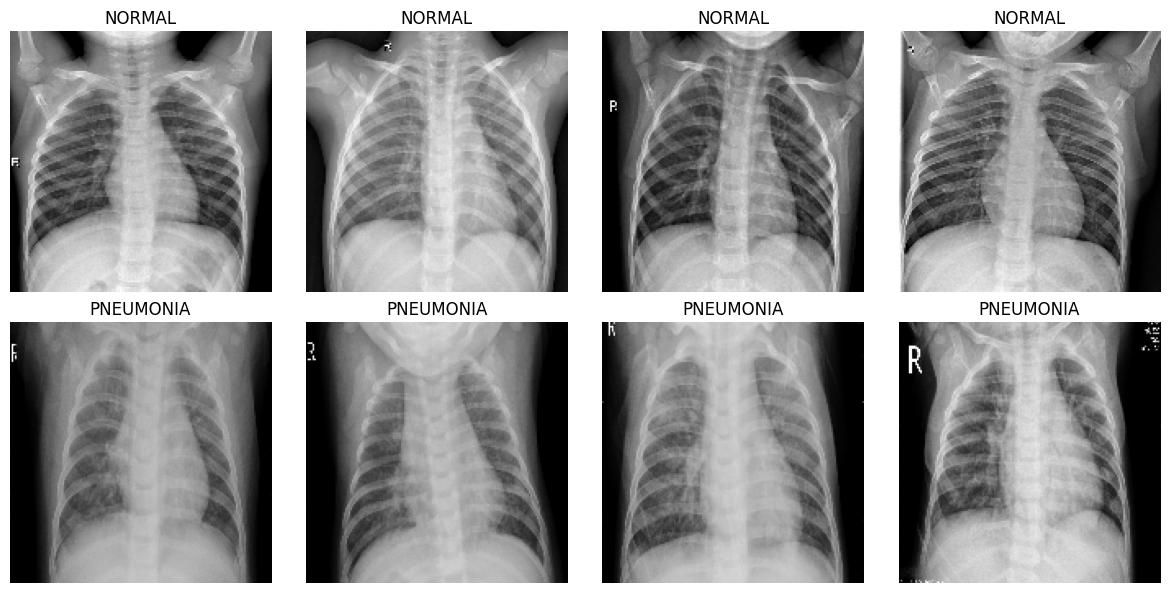

In [5]:
fig, ejes = plt.subplots(2, 4, figsize=(12, 6))
for fila, c in enumerate(clases):
    ejemplos = rutas_train[y_train == fila][:4]
    for k, r in enumerate(ejemplos):
        img, _ = cargar(r, 0)
        ejes[fila, k].imshow(img.numpy().squeeze(), cmap="gray")
        ejes[fila, k].set_title(c)
        ejes[fila, k].axis("off")
plt.tight_layout()
plt.savefig("figuras/ejemplos.png", dpi=150)
plt.show()

In [6]:
# pesos por clase para compensar el desbalance
n = len(y_train)
pesos_clase = {0: n / (2 * (y_train == 0).sum()), 1: n / (2 * (y_train == 1).sum())}
print("pesos por clase:", {clases[k]: round(float(v), 3) for k, v in pesos_clase.items()})

pesos por clase: {'NORMAL': 1.939, 'PNEUMONIA': 0.674}


## Modelo 1: CNN desde cero
Cuatro bloques convolucionales con data augmentation, Dropout y Early Stopping.

In [7]:
aumento = tf.keras.Sequential([
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.05, 0.05),
], name="aumento")

cnn = models.Sequential([
    layers.Input(shape=(IMG, IMG, 3)),
    aumento,
    layers.Rescaling(1. / 255),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.5),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(1, activation="sigmoid"),
], name="cnn_desde_cero")
cnn.summary()

Model: "cnn_desde_cero"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ aumento (Sequential)            │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 160, 160, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 80, 80, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 80, 80, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 40, 40, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 40, 40, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 20, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 20, 20, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 10, 10, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12800)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,638,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,879,489 (7.17 MB)

 Trainable params: 1,879,489 (7.17 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
metricas = ["accuracy", tf.keras.metrics.Recall(name="recall"), tf.keras.metrics.Precision(name="precision")]
parada = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

cnn.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=metricas)
inicio = time.time()
hist_cnn = cnn.fit(train_ds, validation_data=val_ds, epochs=25, class_weight=pesos_clase, callbacks=[parada], verbose=2)
tiempo_cnn = time.time() - inicio
print(f"tiempo CNN: {tiempo_cnn:.1f} s, epocas: {len(hist_cnn.history['loss'])}")

Epoch 1/25


C:\Users\maxjo\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


139/139 - 21s - 151ms/step - accuracy: 0.5671 - loss: 0.6534 - precision: 0.8254 - recall: 0.5285 - val_accuracy: 0.7134 - val_loss: 0.5179 - val_precision: 0.9366 - val_recall: 0.6587


Epoch 2/25


139/139 - 18s - 126ms/step - accuracy: 0.7763 - loss: 0.4591 - precision: 0.9208 - recall: 0.7642 - val_accuracy: 0.8994 - val_loss: 0.2891 - val_precision: 0.9922 - val_recall: 0.8714


Epoch 3/25


... (8 outputs left out)

139/139 - 18s - 128ms/step - accuracy: 0.9328 - loss: 0.1746 - precision: 0.9771 - recall: 0.9312 - val_accuracy: 0.9134 - val_loss: 0.2183 - val_precision: 0.9981 - val_recall: 0.8851


Epoch 8/25


139/139 - 18s - 128ms/step - accuracy: 0.9346 - loss: 0.1545 - precision: 0.9796 - recall: 0.9312 - val_accuracy: 0.9146 - val_loss: 0.2099 - val_precision: 0.9981 - val_recall: 0.8868


tiempo CNN: 145.1 s, epocas: 8


## Modelo 2: Transfer learning con MobileNetV2
Primero se entrena solo la capa final con el modelo base congelado y después se hace fine-tuning de las últimas 30 capas con una tasa de aprendizaje baja.

In [9]:
modelo_base = tf.keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, weights="imagenet")
modelo_base.trainable = False

entradas = tf.keras.Input(shape=(IMG, IMG, 3))
x = aumento(entradas)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = modelo_base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
salidas = layers.Dense(1, activation="sigmoid")(x)
tl = tf.keras.Model(entradas, salidas, name="mobilenetv2_tl")
tl.summary()

tl.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=metricas)
inicio = time.time()
hist_tl = tl.fit(train_ds, validation_data=val_ds, epochs=10, class_weight=pesos_clase, callbacks=[parada], verbose=2)
tiempo_tl = time.time() - inicio
print(f"tiempo transfer learning: {tiempo_tl:.1f} s")

Model: "mobilenetv2_tl"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ aumento (Sequential)            │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/10


... (16 outputs left out)

139/139 - 18s - 128ms/step - accuracy: 0.9373 - loss: 0.1590 - precision: 0.9818 - recall: 0.9327 - val_accuracy: 0.9159 - val_loss: 0.2152 - val_precision: 0.9887 - val_recall: 0.8971


Epoch 10/10


139/139 - 18s - 130ms/step - accuracy: 0.9364 - loss: 0.1518 - precision: 0.9806 - recall: 0.9327 - val_accuracy: 0.9210 - val_loss: 0.1935 - val_precision: 0.9851 - val_recall: 0.9074


tiempo transfer learning: 181.6 s


In [10]:
# fine-tuning: se descongelan las ultimas 30 capas del modelo base
modelo_base.trainable = True
for capa in modelo_base.layers[:-30]:
    capa.trainable = False

tl.compile(optimizer=tf.keras.optimizers.Adam(1e-5), loss="binary_crossentropy", metrics=metricas)
inicio = time.time()
hist_ft = tl.fit(train_ds, validation_data=val_ds, epochs=10, class_weight=pesos_clase, callbacks=[parada], verbose=2)
tiempo_ft = time.time() - inicio
print(f"tiempo fine-tuning: {tiempo_ft:.1f} s")
print(f"parametros entrenables en fine-tuning: {sum(int(np.prod(v.shape)) for v in tl.trainable_variables)}")

Epoch 1/10


139/139 - 29s - 206ms/step - accuracy: 0.9188 - loss: 0.2398 - precision: 0.9601 - recall: 0.9297 - val_accuracy: 0.9439 - val_loss: 0.1630 - val_precision: 0.9804 - val_recall: 0.9434


Epoch 2/10


139/139 - 24s - 174ms/step - accuracy: 0.9292 - loss: 0.1828 - precision: 0.9767 - recall: 0.9267 - val_accuracy: 0.9439 - val_loss: 0.1639 - val_precision: 0.9804 - val_recall: 0.9434


Epoch 3/10


139/139 - 24s - 175ms/step - accuracy: 0.9337 - loss: 0.1601 - precision: 0.9799 - recall: 0.9297 - val_accuracy: 0.9401 - val_loss: 0.1642 - val_precision: 0.9820 - val_recall: 0.9365


... (11 outputs left out)

139/139 - 24s - 173ms/step - accuracy: 0.9557 - loss: 0.1121 - precision: 0.9871 - recall: 0.9527 - val_accuracy: 0.9541 - val_loss: 0.1330 - val_precision: 0.9824 - val_recall: 0.9554


Epoch 10/10


139/139 - 24s - 176ms/step - accuracy: 0.9586 - loss: 0.1094 - precision: 0.9860 - recall: 0.9579 - val_accuracy: 0.9516 - val_loss: 0.1331 - val_precision: 0.9840 - val_recall: 0.9503


tiempo fine-tuning: 246.9 s
parametros entrenables en fine-tuning: 1527681


## Curvas de entrenamiento

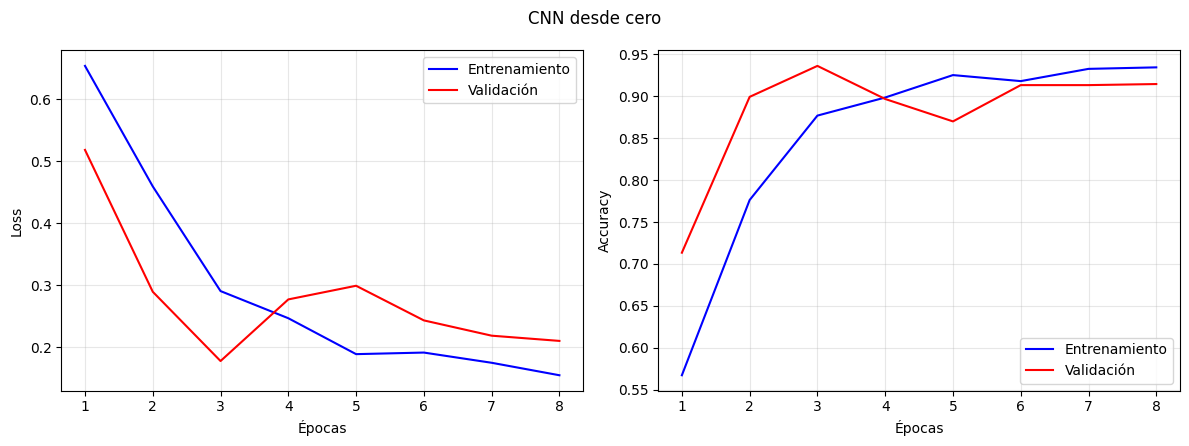

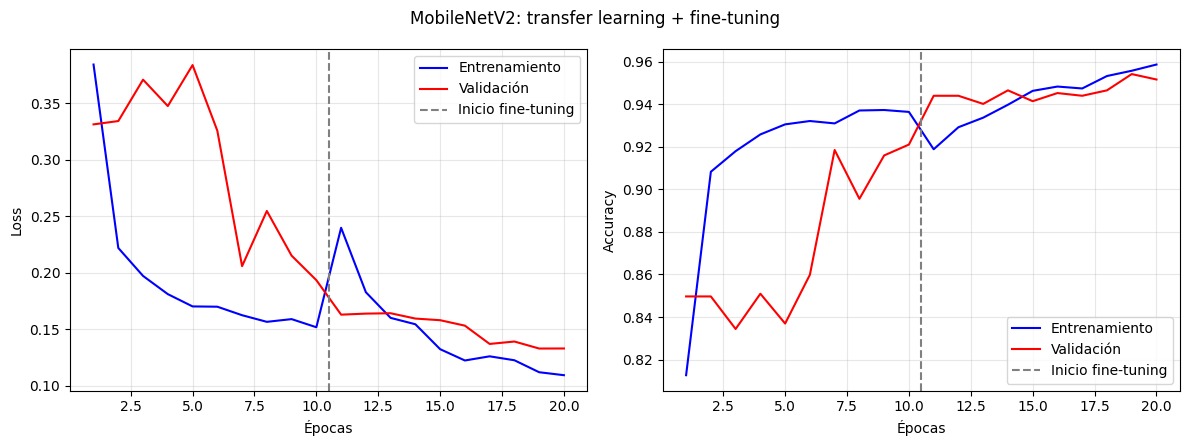

In [11]:
def curvas(historiales, titulo, archivo, corte=None):
    h = {k: sum([hh.history[k] for hh in historiales], []) for k in ["loss", "val_loss", "accuracy", "val_accuracy"]}
    epocas = range(1, len(h["loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
    ax1.plot(epocas, h["loss"], "b", label="Entrenamiento")
    ax1.plot(epocas, h["val_loss"], "r", label="Validación")
    ax1.set_xlabel("Épocas")
    ax1.set_ylabel("Loss")
    ax2.plot(epocas, h["accuracy"], "b", label="Entrenamiento")
    ax2.plot(epocas, h["val_accuracy"], "r", label="Validación")
    ax2.set_xlabel("Épocas")
    ax2.set_ylabel("Accuracy")
    for ax in (ax1, ax2):
        if corte:
            ax.axvline(corte + 0.5, color="gray", linestyle="--", label="Inicio fine-tuning")
        ax.legend()
        ax.grid(alpha=0.3)
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.savefig(archivo, dpi=150)
    plt.show()

curvas([hist_cnn], "CNN desde cero", "figuras/curvas_cnn.png")
curvas([hist_tl, hist_ft], "MobileNetV2: transfer learning + fine-tuning", "figuras/curvas_tl.png", corte=len(hist_tl.history["loss"]))

## Evaluación en el conjunto de prueba

CNN desde cero
              precision    recall  f1-score   support

      NORMAL     0.9189    0.5812    0.7120       234
   PNEUMONIA     0.7941    0.9692    0.8730       390

    accuracy                         0.8237       624
   macro avg     0.8565    0.7752    0.7925       624
weighted avg     0.8409    0.8237    0.8126       624



MobileNetV2 (TL + FT)
              precision    recall  f1-score   support

      NORMAL     0.9302    0.6838    0.7882       234
   PNEUMONIA     0.8363    0.9692    0.8979       390

    accuracy                         0.8622       624
   macro avg     0.8833    0.8265    0.8430       624
weighted avg     0.8715    0.8622    0.8567       624



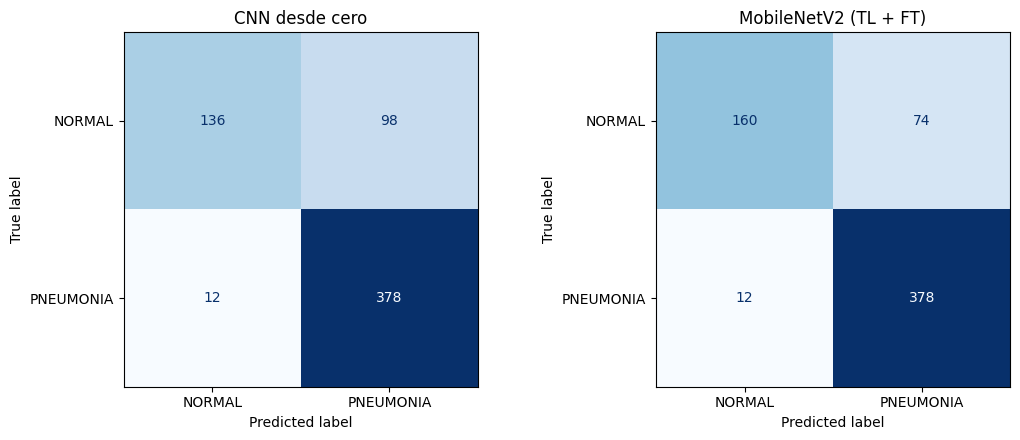

In [12]:
resultados = {}
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5))
for eje, (nombre, modelo) in zip(ejes, [("CNN desde cero", cnn), ("MobileNetV2 (TL + FT)", tl)]):
    prob = modelo.predict(test_ds, verbose=0).ravel()
    pred = (prob >= 0.5).astype(int)
    resultados[nombre] = {
        "accuracy": float((pred == y_test).mean()),
        "precision": precision_score(y_test, pred),
        "recall": recall_score(y_test, pred),
        "f1": f1_score(y_test, pred),
        "auc": roc_auc_score(y_test, prob),
        "parametros": modelo.count_params(),
    }
    print(nombre)
    print(classification_report(y_test, pred, target_names=clases, digits=4))
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=clases).plot(ax=eje, cmap="Blues", colorbar=False)
    eje.set_title(nombre)
plt.tight_layout()
plt.savefig("figuras/matrices_confusion.png", dpi=150)
plt.show()

In [13]:
tiempos = {"CNN desde cero": tiempo_cnn, "MobileNetV2 (TL + FT)": tiempo_tl + tiempo_ft}
print(f"{'modelo':24s} {'accuracy':>9s} {'precision':>10s} {'recall':>8s} {'f1':>8s} {'auc':>8s} {'parametros':>11s} {'tiempo':>8s}")
for nombre, r in resultados.items():
    print(f"{nombre:24s} {r['accuracy']:9.4f} {r['precision']:10.4f} {r['recall']:8.4f} {r['f1']:8.4f} {r['auc']:8.4f} {r['parametros']:11d} {tiempos[nombre]:7.1f}s")

modelo                    accuracy  precision   recall       f1      auc  parametros   tiempo
CNN desde cero              0.8237     0.7941   0.9692   0.8730   0.9151     1879489   145.1s
MobileNetV2 (TL + FT)       0.8622     0.8363   0.9692   0.8979   0.9591     2259265   428.5s
